# 02 · Análisis Exploratorio de Datos (EDA) y limpieza
## Departamentos en venta 2019 — CABA

Este notebook sigue la secuencia de trabajo del material de la cátedra:

| Sección | Contenido | Material de referencia |
|---|---|---|
| 1 | Comprender antes de modelar (documento de decisión) | M3-3 Laboratorio Bank Marketing |
| 2 | Carga y primera exploración | SQL_03 Ejercicio 1 · M3-2 "Explorar antes de modelar" |
| 3 | Auditoría de calidad, outliers IQR y límites de dominio | Laboratorio Prompting, Fase A (`auditar_dataset`) · M3-3 Hito A |
| 4 | Problemas puntuales detectados | — |
| 5 | Limpieza de datos inválidos y verificación | M1-1 (Preprocesamiento) · M2-1 (funciones puras) · M3-2 (`assert`) |
| 6 | Visualización: cuatro gráficas comodín | M5-3 Cuatro gráficas comodín |
| 7 | Variable objetivo y su distribución | M3-3 Hito A ("distribución de y") |
| 8 | Definición de X e y y variables excluidas | M3-3 Hito A |
| 9 | Conclusiones | M1-1 (EDA: patrones, sesgos, hipótesis) |
| 10 | Dataset limpio y persistencia | Consigna TP (Tabla 1: datos limpios) |

> **Qué se limpia acá y qué no.** En el ciclo de vida del proyecto (M1-1) el *preprocesamiento* va antes del *EDA*. Acá se corrigen solo datos **inválidos** (filas que no corresponden, valores imposibles, errores de carga) con reglas fijas que no se aprenden de los datos. La **imputación, el escalado y la codificación** se hacen dentro del `Pipeline` / `ColumnTransformer` en el notebook de modelado, después de separar train/test, como en M3-3 y en la Fase B del Laboratorio Prompting.
>
> **Dónde está el código.** La carga (`src/carga.py`), el diagnóstico (`src/calidad.py`) y la limpieza (`src/limpieza.py`) viven en módulos con funciones puras y tests (`tests/test_limpieza.py`). Este notebook las usa para analizar y documentar las decisiones.

### Relación con el documento *Segmentación de valor – Departamentos CABA 2019*

- **El documento** explica cómo segmenta el mercado inmobiliario de CABA. Es el fundamento del objetivo y del criterio de segmentación (secciones 1 y 7).
- **Este notebook** muestra qué se encontró en los datos y qué se decidió (secciones 2 a 6).
- **El vínculo** es el criterio de segmentación (sección 7): el recálculo del precio por m² de febrero (sección 4) permite aplicarlo de forma homogénea a todo el dataset.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.append(str(Path('..').resolve()))
from src.calidad import auditar_dataset, resumen_outliers_iqr
from src.carga import cargar_dbf
from src.config import OUTPUTS_DIR, RUTA_DBF
from src.limpieza import (COLUMNA_ID, COLUMNAS_DESCARTADAS, LIMITES, LIMITES_USD_M2,
                          limpiar_datos)
from src.logger import crear_logger

logger = crear_logger(OUTPUTS_DIR / 'eda' / 'eda.log')

MESES = ['ENERO', 'FEBRERO', 'MARZO', 'ABRIL', 'JUNIO', 'JULIO', 'AGOSTO',
         'SEPTIEMBRE', 'OCTUBRE', 'NOVIEMBRE', 'DICIEMBRE']  # MAYO no tiene datos

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.2f}'.format)

## 1. Comprender antes de modelar
*(Estructura del "Documento de decisión A" del laboratorio M3-3.)*

Cada fila es una publicación de un departamento en venta en CABA durante 2019 (portal BA Data). Variables disponibles:

| Grupo | Variables | Significado |
|---|---|---|
| Operación | `OPERACION`, `TIPO`, `MES` | Venta/alquiler, tipo de inmueble, mes de publicación |
| Superficie | `M2TOTAL`, `M2CUB` | Metros totales y cubiertos |
| Composición | `AMBIENTES`, `BANOS` | Cantidad de ambientes y baños |
| Antigüedad | `ANTIG`, `AGE` | Años del inmueble; `EST` = a estrenar |
| Ubicación | `BARRIOS_1`, `COMUNAS`, `LATITUD`, `LONGITUD`, `DIRECCION` | Dónde está |
| Precio | `PRECIOUSD`, `PRECIOARS`, `PRECIOUSDM`, `PRECIOARSM`, `CAMBIO` | Precio publicado total y por m², tipo de cambio |

**Unidad de análisis:** un departamento publicado en venta.

**Objetivo:** predecir el *segmento de valor* (Económico / Medio / Premium) definido por el precio publicado por m² cubierto (terciles). El concepto de segmento de valor y el criterio de segmentación se fundamentan en el documento *Segmentación de valor – Departamentos CABA 2019*, que describe cómo segmenta el mercado inmobiliario de CABA (ver sección 7).

**Momento de predicción:** antes de fijar o publicar el precio, cuando se conocen solo las características del inmueble.

**Uso previsto:** orientar la tasación y detectar publicaciones con precio atípico para sus características (posible sobrevaluación o subvaluación).

**Variables que no estarán disponibles al predecir (fuga de información):** todas las de precio (`PRECIOUSD`, `PRECIOARS`, `PRECIOUSDM`, `PRECIOARSM`) y `CAMBIO`. Se usan solo para construir la variable objetivo.

## 2. Carga y primera exploración
*(SQL_03 Ejercicio 1: primeras filas, tipos, nulos y qué información contiene el dataset.)*

In [2]:
df_raw = cargar_dbf(RUTA_DBF)
print(f'Dimensiones: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas')
print(f'Filas duplicadas: {df_raw.duplicated().sum()}')
df_raw.head()

2026-11-13 20:10:09,656 | INFO | src.carga | Carga: inicio. Archivo=data\Departamentos_venta_2019.dbf


2026-11-13 20:10:12,431 | INFO | src.carga | Carga: 88640 filas y 19 columnas leídas.


Dimensiones: 88,640 filas x 19 columnas
Filas duplicadas: 98


,OPERACION,TIPO,ANTIG,AGE,M2TOTAL,M2CUB,AMBIENTES,BANOS,DIRECCION,CAMBIO,PRECIOUSD,PRECIOARS,PRECIOUSDM,PRECIOARSM,BARRIOS_1,COMUNAS,MES,LATITUD,LONGITUD
0,VTA,DTO,0.00,EST,20.00,20.00,1.00,1.00,Leiva al 4000,43.74,"52,000.00","2,274,480.00",2600,"113,724.00",CHACARITA,15,JUNIO,-34.59,-58.45
1,VTA,DTO,0.00,EST,58.00,50.00,2.00,1.00,Colegiales,43.74,"140,693.00","6,153,911.00",2813,"123,041.00",CHACARITA,15,JUNIO,-34.58,-58.46
2,VTA,DTO,0.00,EST,36.00,34.00,1.00,1.00,Leiva 4345 4 B,43.74,"85,000.00","3,717,900.00",2500,"109,350.00",CHACARITA,15,JUNIO,-34.59,-58.45
3,VTA,DTO,0.00,EST,24.00,22.00,1.00,1.00,Paysandu 1970,43.74,"68,900.00","3,013,686.00",3131,"136,950.00",PATERNAL,15,JUNIO,-34.60,-58.46
4,VTA,DTO,0.00,EST,45.00,45.00,2.00,1.00,Avenida Estado DE Israel al 4600,43.74,"199,999.00","8,747,956.00",4444,"194,381.00",VILLA CRESPO,15,JUNIO,-34.60,-58.43


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 88640 entries, 0 to 88639
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   OPERACION   88640 non-null  str    
 1   TIPO        88640 non-null  str    
 2   ANTIG       88640 non-null  float64
 3   AGE         88640 non-null  str    
 4   M2TOTAL     88640 non-null  float64
 5   M2CUB       88640 non-null  float64
 6   AMBIENTES   88640 non-null  float64
 7   BANOS       88640 non-null  float64
 8   DIRECCION   88640 non-null  str    
 9   CAMBIO      88640 non-null  str    
 10  PRECIOUSD   88640 non-null  float64
 11  PRECIOARS   88640 non-null  float64
 12  PRECIOUSDM  88640 non-null  int64  
 13  PRECIOARSM  88640 non-null  float64
 14  BARRIOS_1   88640 non-null  str    
 15  COMUNAS     88640 non-null  int64  
 16  MES         88640 non-null  str    
 17  LATITUD     88640 non-null  float64
 18  LONGITUD    88640 non-null  float64
dtypes: float64(10), int64(2), str(7)
mem

In [4]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
ANTIG,"88,640.00",22.42,23.10,-81.00,0.00,13.00,40.00,170.00
M2TOTAL,"88,640.00",81.43,133.99,0.00,42.00,61.00,93.00,"17,180.00"
M2CUB,"88,640.00",70.81,66.26,0.00,38.00,55.00,82.00,"6,756.00"
AMBIENTES,"88,640.00",2.64,1.74,0.00,2.00,3.00,3.00,321.00
BANOS,"88,640.00",1.41,1.00,0.00,1.00,1.00,2.00,132.00
PRECIOUSD,"88,640.00","256,550.33","335,378.43","9,000.00","115,000.00","165,000.00","270,000.00","38,238,668.00"
PRECIOARS,"88,640.00","12,626,726.80","15,853,133.42",0.00,"5,494,580.00","8,128,200.00","13,468,000.00","475,200,000.00"
PRECIOUSDM,"88,640.00","3,268.57","1,215.38",270.00,"2,503.00","3,058.00","3,725.00","30,555.00"
PRECIOARSM,"88,640.00","164,456.16","91,093.32",0.00,"119,917.00","151,250.00","191,888.25","9,984,000.00"
COMUNAS,"88,640.00",8.68,5.09,0.00,3.00,10.00,13.00,15.00


## 3. Auditoría de calidad
*(Función `auditar_dataset` del Laboratorio Prompting, Fase A, y auditoría por columna del Hito A de M3-3.)*

### 3.1 Tipos, faltantes, ceros y valores únicos

In [5]:
auditar_dataset(df_raw)

,tipo,nulos,pct_nulos,ceros,valores_unicos
OPERACION,str,0,0.00,NaN,2
TIPO,str,0,0.00,NaN,2
ANTIG,float64,0,0.00,"28,342.00",127
AGE,str,0,0.00,NaN,2
M2TOTAL,float64,0,0.00,"1,919.00",582
M2CUB,float64,0,0.00,"2,109.00",498
AMBIENTES,float64,0,0.00,842.00,26
BANOS,float64,0,0.00,"2,241.00",18
DIRECCION,str,0,0.00,NaN,44378
CAMBIO,str,0,0.00,NaN,17


### 3.2 Outliers por rango intercuartílico (IQR)
Es outlier todo valor menor que Q1 − 1,5·IQR o mayor que Q3 + 1,5·IQR.

In [6]:
columnas_numericas = ['PRECIOUSD', 'PRECIOUSDM', 'M2TOTAL', 'M2CUB', 'AMBIENTES', 'BANOS', 'ANTIG']
resumen_outliers_iqr(df_raw, columnas_numericas)

,lim_inferior,lim_superior,outliers,pct_outliers
columna,,,,
PRECIOUSD,"-117,500.00","502,500.00",7929,8.95
PRECIOUSDM,670.00,"5,558.00",4192,4.73
M2TOTAL,-34.50,169.50,6599,7.44
M2CUB,-28.00,148.00,6583,7.43
AMBIENTES,0.50,4.50,6175,6.97
BANOS,-0.50,3.50,2256,2.55
ANTIG,-60.00,100.00,127,0.14


### 3.3 ¿IQR o límites de dominio para el precio por m²?
El IQR supone una distribución más o menos simétrica. El precio por m² tiene una **cola derecha natural**: el segmento de lujo. Se mide qué eliminaría el IQR aplicado al precio por m² cubierto, comparado con límites de dominio fijos.

In [7]:
validas = df_raw[(df_raw['OPERACION'] == 'VTA') & (df_raw['TIPO'] == 'DTO')
                 & df_raw['M2CUB'].between(*LIMITES['M2CUB'])]
usd_m2 = (validas['PRECIOUSD'] / validas['M2CUB']).rename('USD_M2')

lim_iqr = resumen_outliers_iqr(usd_m2.to_frame(), ['USD_M2']).loc['USD_M2']
fuera_iqr = ~usd_m2.between(lim_iqr['lim_inferior'], lim_iqr['lim_superior'])
fuera_fijos = ~usd_m2.between(*LIMITES_USD_M2)
print(f"IQR:           {lim_iqr['lim_inferior']:>6,.0f} a {lim_iqr['lim_superior']:>6,.0f} USD/m² -> elimina {fuera_iqr.sum():,} avisos")
print(f"Límites fijos: {LIMITES_USD_M2[0]:>6,} a {LIMITES_USD_M2[1]:>6,} USD/m² -> elimina {fuera_fijos.sum():,} avisos")

# ¿De qué barrios son los avisos que eliminaría el IQR?
(pd.DataFrame({'avisos': validas.groupby('BARRIOS_1').size(),
               'eliminados_por_iqr': fuera_iqr.groupby(validas['BARRIOS_1']).sum()})
   .assign(pct_eliminado=lambda t: (100 * t['eliminados_por_iqr'] / t['avisos']).round(1))
   .sort_values('eliminados_por_iqr', ascending=False)
   .head(6))

IQR:              724 a  5,565 USD/m² -> elimina 4,156 avisos


Límites fijos:    500 a 20,000 USD/m² -> elimina 10 avisos


,avisos,eliminados_por_iqr,pct_eliminado
BARRIOS_1,,,
PALERMO,14599,1641,11.20
PUERTO MADERO,1537,1133,73.70
BELGRANO,7452,585,7.90
RECOLETA,8217,301,3.70
NUÃEZ,2356,128,5.40
RETIRO,2076,74,3.60


In [8]:
# Los avisos que eliminan los límites fijos: ¿son errores de carga?
validas.loc[fuera_fijos, ['BARRIOS_1', 'M2CUB', 'PRECIOUSD']].assign(USD_M2=usd_m2[fuera_fijos].round(0)).sort_values('USD_M2')

,BARRIOS_1,M2CUB,PRECIOUSD,USD_M2
74493,VILLA DEVOTO SUR,442.00,"120,000.00",271.00
81465,RECOLETA,775.00,"210,000.00",271.00
78995,VILLA CRESPO,550.00,"160,000.00",291.00
79320,SAN NICOLAS,28.00,"9,000.00",321.00
29941,BELGRANO,200.00,"66,500.00",332.00
71716,VILLA DEVOTO NORTE,35.00,"14,000.00",400.00
67275,ALMAGRO,43.00,"17,570.00",409.00
77655,SAN NICOLAS,53.00,"1,300,000.00","24,528.00"
26126,PUERTO MADERO,108.00,"3,300,000.00","30,556.00"
86191,RECOLETA,15.00,"590,000.00","39,333.00"


**Decisión: límites de dominio fijos (500 a 20.000 USD/m²), no IQR.**

- El IQR elimina sobre todo **precios reales del segmento de lujo** (Palermo, Puerto Madero, Belgrano, Recoleta): en Puerto Madero deja afuera a la mayoría de los avisos. Eso sesgaría la variable objetivo (los cortes de los terciles bajarían y la clase Premium se "abarataría").
- Además, el IQR se calcula con los datos: aplicado antes del split usaría información del conjunto de prueba, y filtrar filas usando el precio (que define la clase) haría que las métricas en test sean optimistas, porque al predecir no se conoce el precio y no se puede aplicar el mismo filtro.
- Los límites fijos se anclan en el mercado: según el Index Zonaprop (ago-2026) el barrio más barato es Lugano (≈ 1.056 USD/m²) y el más caro Puerto Madero (≈ 6.148 USD/m²); en este dataset las medianas por barrio van de ≈ 963 (Villa Soldati) a ≈ 6.263 (Puerto Madero), y hay proyectos de lujo publicados a ≈ 10.000 USD/m². Los avisos fuera de 500–20.000 son errores de carga evidentes (tabla anterior).
- El IQR se conserva como **diagnóstico** (sección 3.2): para superficie, ambientes y baños también se usan límites de dominio.

## 4. Problemas puntuales detectados
La auditoría general no muestra todo. Se revisaron estos casos:

In [9]:
# a) ¿Cómo está calculado PRECIOUSDM? Se compara con USD/m² cubiertos y con USD/m² totales.
coincide_cub = ((df_raw['PRECIOUSD'] / df_raw['M2CUB'] - df_raw['PRECIOUSDM']).abs()
                / df_raw['PRECIOUSDM'] < 0.05)
coincide_tot = ((df_raw['PRECIOUSD'] / df_raw['M2TOTAL'] - df_raw['PRECIOUSDM']).abs()
                / df_raw['PRECIOUSDM'] < 0.05)
pd.DataFrame({
    '% filas = USD / M2CUB': coincide_cub.groupby(df_raw['MES']).mean() * 100,
    '% filas = USD / M2TOTAL': coincide_tot.groupby(df_raw['MES']).mean() * 100,
}).round(0)

,% filas = USD / M2CUB,% filas = USD / M2TOTAL
MES,,
ABRIL,99.00,43.00
AGOSTO,98.00,37.00
DICIEMBRE,97.00,40.00
ENERO,99.00,46.00
FEBRERO,43.00,100.00
JULIO,97.00,39.00
JUNIO,98.00,40.00
MARZO,99.00,43.00
NOVIEMBRE,97.00,37.00


In [10]:
# Impacto: mediana de PRECIOUSDM original vs. recalculado sobre m² cubiertos, por mes.
validas_m2 = df_raw[df_raw['M2CUB'] > 0]
impacto = pd.DataFrame({
    'PRECIOUSDM original': validas_m2.groupby('MES')['PRECIOUSDM'].median(),
    'USD / M2CUB recalculado': (validas_m2['PRECIOUSD'] / validas_m2['M2CUB']).groupby(validas_m2['MES']).median(),
})
impacto['diferencia %'] = (impacto['PRECIOUSDM original'] / impacto['USD / M2CUB recalculado'] - 1) * 100
impacto.round(1)

,PRECIOUSDM original,USD / M2CUB recalculado,diferencia %
MES,,,
ABRIL,"3,064.50","3,065.00",-0.00
AGOSTO,"3,056.00","3,056.50",-0.00
DICIEMBRE,"3,096.00","3,096.80",-0.00
ENERO,"3,055.00","3,055.60",-0.00
FEBRERO,"2,828.00","3,125.00",-9.50
JULIO,"3,075.00","3,075.00",0.00
JUNIO,"3,088.00","3,088.20",-0.00
MARZO,"3,125.00","3,125.00",0.00
NOVIEMBRE,"3,078.50","3,079.10",-0.00


**Hallazgo: el precio por m² de FEBRERO está calculado con otro criterio.**

En 10 de los 11 meses, `PRECIOUSDM` coincide con `PRECIOUSD / M2CUB` (superficie **cubierta**) en ~97-99 % de las filas. En FEBRERO, en cambio, coincide al 100 % con `PRECIOUSD / M2TOTAL` (superficie **total**). Como la superficie total incluye balcones, terrazas y patios, el precio por m² de febrero queda **subestimado**: su mediana es **~9,5 % más baja** que la recalculada (USD 2.828 vs. 3.125/m²), mientras que en el resto de los meses la diferencia es prácticamente 0 %.

**Por qué importa:** la variable objetivo (segmento de valor) se construye con el precio por m². Si se usara `PRECIOUSDM` tal como viene, los departamentos publicados en febrero tenderían a caer en segmentos más bajos solo por cómo se calculó el precio, no por su valor real.

**Decisión:** se descarta `PRECIOUSDM` y se recalcula `USD_M2 = PRECIOUSD / M2CUB` para **todas** las filas, de modo que el precio por m² quede calculado con un único criterio (superficie cubierta), coherente con el criterio de segmentación definido para la variable objetivo (sección 7).

In [11]:
# b) Coordenadas en 0 (fuera de CABA), por mes.
sin_coord = df_raw['LATITUD'] == 0
print('Filas con LATITUD/LONGITUD = 0:', sin_coord.sum())
print(df_raw.loc[sin_coord, 'MES'].value_counts().to_dict())

# c) Errores de codificación en barrios y comunas inválidas.
print('Barrios mal codificados:', [b for b in df_raw['BARRIOS_1'].dropna().unique() if 'Ã' in b])
print('Filas con COMUNAS = 0:', (df_raw['COMUNAS'] == 0).sum())

# d) Formatos distintos en CAMBIO.
print('Ejemplos de CAMBIO:', df_raw['CAMBIO'].dropna().unique()[:12].tolist())

# e) Filas que no son venta de departamentos.
print('OPERACION:', df_raw['OPERACION'].value_counts().to_dict())
print('TIPO:', df_raw['TIPO'].value_counts().to_dict())

Filas con LATITUD/LONGITUD = 0: 9167
{'SEPTIEMBRE': 9167}
Barrios mal codificados: ['NUÃ\x91EZ', 'NUÃ\x83â\x80\x98EZ']
Filas con COMUNAS = 0: 4
Ejemplos de CAMBIO: ['43.74', '0.00', '45.00', '43,2', '0', '41.40', '37,5', '41,40', '45,00', '43,74', '42,3', '51.80']
OPERACION: {'VTA': 88639, 'ALQ': 1}
TIPO: {'DTO': 88615, 'EDIFICIO': 25}


In [12]:
# f) Valores imposibles o fuera de dominio.
pd.DataFrame({
    'en_cero': (df_raw[list(LIMITES)] == 0).sum(),
    'negativos': (df_raw[list(LIMITES)] < 0).sum(),
    'maximo': df_raw[list(LIMITES)].max(),
    'rango_aceptado': pd.Series({k: f'{a} a {b}' for k, (a, b) in LIMITES.items()}),
})

,en_cero,negativos,maximo,rango_aceptado
M2CUB,2109,0,"6,756.00",15 a 1000
M2TOTAL,1919,0,"17,180.00",15 a 2000
AMBIENTES,842,0,321.00,1 a 15
BANOS,2241,0,132.00,1 a 10
ANTIG,28342,4,170.00,0 a 150


In [13]:
# g) ¿ANTIG = 0 significa "a estrenar"? Se cruza con la marca AGE = 'EST' por mes.
ventas = df_raw[(df_raw['OPERACION'] == 'VTA') & (df_raw['TIPO'] == 'DTO')]
cero_sin_marca = (ventas['ANTIG'] == 0) & (ventas['AGE'] != 'EST')
print(f'ANTIG = 0 sin la marca EST: {cero_sin_marca.sum():,} avisos')
(pd.crosstab(ventas['MES'], cero_sin_marca)
   .rename(columns={False: 'resto', True: 'ANTIG=0 sin EST'})
   .rename_axis(columns=None)
   .reindex(MESES))

ANTIG = 0 sin la marca EST: 11,801 avisos


,resto,ANTIG=0 sin EST
MES,,
ENERO,3994,0
FEBRERO,5569,1389
MARZO,6822,0
ABRIL,4389,0
JUNIO,15294,1420
JULIO,4148,768
AGOSTO,7525,1614
SEPTIEMBRE,7563,1604
OCTUBRE,8498,2273


**Hallazgo: `ANTIG = 0` mezcla "a estrenar" con "sin dato".** En ENERO, MARZO y ABRIL no hay ningún aviso con antigüedad 0 sin la marca `EST`; en el resto de los meses hay cientos o miles. El patrón depende del **mes de carga**, no del inmueble: en esos meses la antigüedad faltante se cargó como 0. Si se dejara así, el modelo vería como "nuevos" a miles de departamentos de antigüedad desconocida.

**Decisión:** `ANTIG = 0` sin la marca `EST` pasa a nulo y se imputa en el Pipeline con indicador de faltante (`SimpleImputer(add_indicator=True)`).

**Resumen de problemas:**

1. **`PRECIOUSDM` no es consistente:** en FEBRERO se calcula sobre superficie *total* y en el resto de los meses sobre superficie *cubierta*. Como de ahí sale la variable objetivo, se recalcula para todas las filas como `USD_M2 = PRECIOUSD / M2CUB`.
2. **SEPTIEMBRE no tiene coordenadas** (`LATITUD`/`LONGITUD` = 0). Se pasan a nulo; barrio y comuna siguen disponibles.
3. **Errores de codificación:** `NUÑEZ` aparece también como `NUÃ‘EZ` (una capa de error) y `NUÃƒâ€˜EZ` (dos capas). Son el mismo barrio.
4. **Barrios vacíos** y **`COMUNAS = 0`** (CABA tiene comunas 1 a 15).
5. **`CAMBIO`** mezcla coma y punto decimal y tiene ceros.
6. **Valores imposibles:** superficies, ambientes y baños en 0, antigüedades negativas y máximos absurdos.
7. **`ANTIG = 0` sin la marca "a estrenar"** en algunos meses: es un dato faltante cargado como 0.
8. **Filas que no corresponden:** edificios completos y un alquiler.

## 5. Limpieza de datos inválidos
Decisiones aplicadas por `limpiar_datos()` (`src/limpieza.py`). Cada fila de la tabla es una función pura; `limpiar_datos` las compone y registra cuántas filas quedan después de cada paso.

| Problema | Decisión | Por qué |
|---|---|---|
| Edificios y alquileres | Eliminar filas | No son el objeto de estudio |
| Duplicados exactos | Eliminar | Misma publicación cargada dos veces |
| `NUÃ‘EZ` / `NUÃƒâ€˜EZ` | Unificar con `NUÑEZ` | Error de codificación (simple y doble) |
| Barrio vacío | Eliminar fila | Sin ubicación no se puede segmentar |
| Comuna 0 | Completar con la comuna más frecuente del barrio | El barrio determina la comuna |
| Coordenadas fuera de CABA (incluye 0) | Pasar a nulo | Se imputan en el Pipeline |
| `ANTIG = 0` sin marca `EST` | Pasar a nulo | Dato faltante cargado como 0 (sección 4.g) |
| Valores fuera de dominio | Pasar a nulo | Se imputan en el Pipeline; no se pierde la fila |
| `M2CUB` > `M2TOTAL` | `M2TOTAL` a nulo | Inconsistente; se conserva la superficie cubierta |
| Sin `M2CUB` válida | Eliminar fila | Sin superficie no hay precio por m² |
| `PRECIOUSDM` inconsistente | Recalcular `USD_M2` | Criterio único para la variable objetivo |
| `USD_M2` fuera de 500–20.000 | Eliminar fila | Errores de carga; límites de dominio, no IQR (sección 3.3) |
| Antigüedad | Crear `TRAMO_ANTIG` | Variable más interpretable |
| Duplicados tras descartar columnas | Eliminar | Misma publicación con distinto texto libre |

**¿Por qué límites de dominio y no IQR?** En todas las variables (superficie, ambientes, baños y también precio por m²) se usan límites que solo descartan valores **imposibles**. El IQR marcaría como outliers a departamentos grandes o de lujo que son reales (ver 3.3).

In [14]:
df, registro = limpiar_datos(df_raw)

pasos = pd.DataFrame(registro, columns=['paso', 'filas'])
pasos['eliminadas'] = (-pasos['filas'].diff()).fillna(0).astype(int)
print(f'Filas conservadas: {len(df):,} de {len(df_raw):,} ({len(df) / len(df_raw):.1%})')
pasos

2026-11-13 20:10:12,898 | INFO | src.limpieza | Limpieza: inicio con 88640 filas.


2026-11-13 20:10:12,921 | INFO | src.limpieza | Limpieza: Solo ventas de departamentos -> 26 filas eliminadas.


2026-11-13 20:10:13,031 | INFO | src.limpieza | Limpieza: Sin duplicados exactos -> 98 filas eliminadas.


2026-11-13 20:10:13,103 | INFO | src.limpieza | Limpieza: Barrios normalizados -> 2 filas eliminadas.


2026-11-13 20:10:13,241 | INFO | src.limpieza | Limpieza: Con superficie cubierta válida -> 2158 filas eliminadas.


2026-11-13 20:10:13,272 | INFO | src.limpieza | Limpieza: USD_M2 dentro de límites de dominio -> 10 filas eliminadas.


... (7 outputs left out)

2026-11-13 20:10:13,351 | WARNING | src.limpieza | Limpieza: TRAMO_ANTIG con 11471 nulos (se imputan en el Pipeline).


2026-11-13 20:10:13,352 | INFO | src.limpieza | Limpieza: fin. 85357 de 88640 filas conservadas (96.3 %).


Filas conservadas: 85,357 de 88,640 (96.3%)


,paso,filas,eliminadas
0,Datos originales,88640,0
1,Solo ventas de departamentos,88614,26
2,Sin duplicados exactos,88516,98
3,Barrios normalizados,88514,2
4,Comunas completas,88514,0
5,Coordenadas fuera de CABA a nulo,88514,0
6,Antigüedad 0 sin marca 'a estrenar' a nulo,88514,0
7,Valores fuera de dominio a nulo,88514,0
8,M2TOTAL inconsistente a nulo,88514,0
9,Con superficie cubierta válida,86356,2158


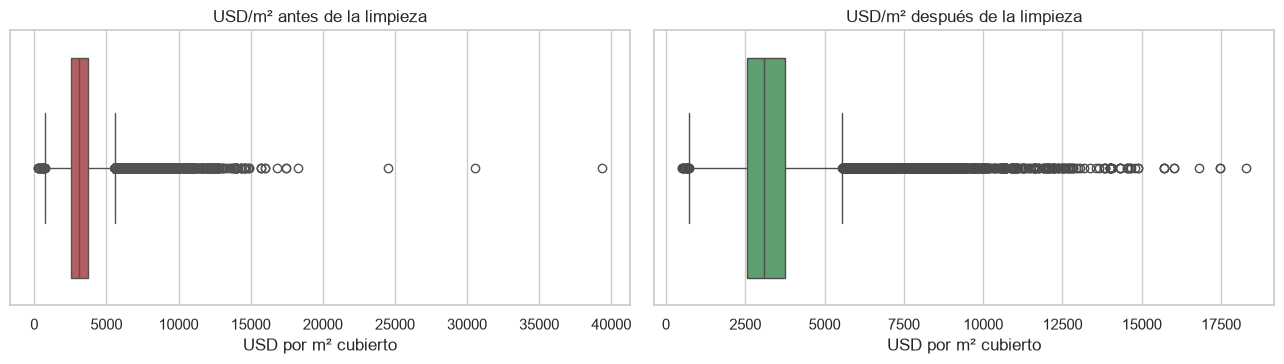

Rango final de USD_M2: 516 a 18,280


In [15]:
# Precio por m² antes y después de quitar outliers.
validas = df_raw[(df_raw['M2CUB'] >= 15) & (df_raw['OPERACION'] == 'VTA') & (df_raw['TIPO'] == 'DTO')]
usd_m2_antes = validas['PRECIOUSD'] / validas['M2CUB']

fig, ejes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.boxplot(x=usd_m2_antes, ax=ejes[0], color='#c44e52')
ejes[0].set_title('USD/m² antes de la limpieza')
sns.boxplot(x=df['USD_M2'], ax=ejes[1], color='#55a868')
ejes[1].set_title('USD/m² después de la limpieza')
for eje in ejes:
    eje.set_xlabel('USD por m² cubierto')
plt.tight_layout()
plt.show()
print(f"Rango final de USD_M2: {df['USD_M2'].min():,.0f} a {df['USD_M2'].max():,.0f}")

### 5.1 Auditoría después de la limpieza y verificación (`assert`, como en M3-2)

In [16]:
auditar_dataset(df)

,tipo,nulos,pct_nulos,ceros,valores_unicos
ID_PROPIEDAD,int64,0,0.00,1.00,85357
ANTIG,float64,11471,13.44,"15,588.00",122
M2TOTAL,float64,2592,3.04,0.00,522
M2CUB,float64,0,0.00,0.00,466
AMBIENTES,float64,767,0.90,0.00,15
BANOS,float64,2053,2.41,0.00,10
PRECIOUSD,float64,0,0.00,0.00,6997
BARRIOS_1,str,0,0.00,NaN,51
COMUNAS,int64,0,0.00,0.00,15
MES,str,0,0.00,NaN,11


In [17]:
columnas_sin_id = [c for c in df.columns if c != COLUMNA_ID]
assert df.duplicated(subset=columnas_sin_id).sum() == 0, 'Quedan duplicados.'
assert df[COLUMNA_ID].is_unique, 'El identificador no es único.'
assert df['M2CUB'].between(*LIMITES['M2CUB']).all(), 'Hay superficies cubiertas fuera de rango.'
assert df['USD_M2'].between(*LIMITES_USD_M2).all(), 'Hay precios por m² fuera de rango.'
assert df['COMUNAS'].between(1, 15).all(), 'Hay comunas inválidas.'
assert not df['BARRIOS_1'].str.contains('Ã').any(), 'Quedan barrios mal codificados.'
assert not df.columns.isin(list(COLUMNAS_DESCARTADAS)).any(), 'Quedaron columnas descartadas.'
assert df_raw.shape == (88_640, 19), 'Se modificó el DataFrame original.'
print('Verificaciones superadas.')

Verificaciones superadas.


Los nulos que quedan (coordenadas de SEPTIEMBRE, antigüedad sin dato, valores fuera de dominio pasados a nulo) se **imputan dentro del Pipeline** con `SimpleImputer(add_indicator=True)`, ajustado solo con train. El indicador le permite al modelo saber que el dato faltaba.

## 6. Visualización: cuatro gráficas comodín
*(M5-3: "la pregunta decide la gráfica". Cada gráfico responde una pregunta.)*

| Gráfica | Para qué | Pregunta en este dataset |
|---|---|---|
| Barras | Comparar categorías | ¿Qué barrios tienen el m² más caro? |
| Circular | Composición de un total | ¿Cómo se reparten las publicaciones por antigüedad? |
| Líneas | Seguir una medida en el tiempo | ¿Cambia el precio por m² a lo largo del año? |
| Dispersión | Relación entre dos cantidades | ¿Los departamentos más grandes tienen m² más caro? |

Antes, la distribución de la variable principal:

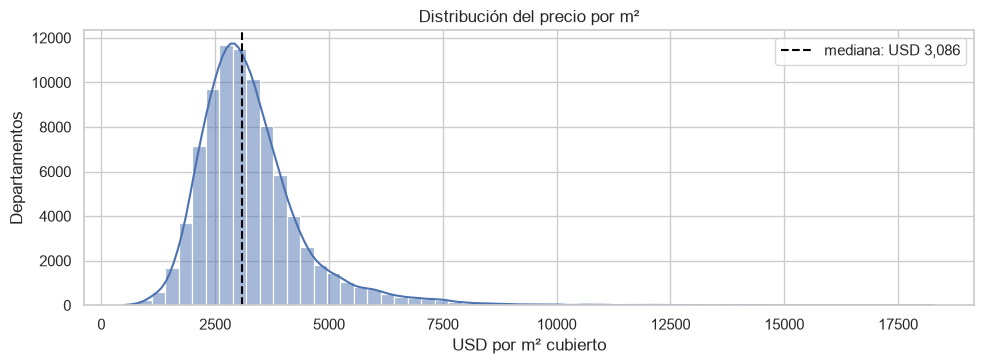

In [18]:
fig, eje = plt.subplots(figsize=(10, 3.8))
sns.histplot(df['USD_M2'], bins=60, kde=True, ax=eje)
eje.axvline(df['USD_M2'].median(), color='black', ls='--',
            label=f"mediana: USD {df['USD_M2'].median():,.0f}")
eje.set_title('Distribución del precio por m²')
eje.set_xlabel('USD por m² cubierto')
eje.set_ylabel('Departamentos')
eje.legend()
plt.tight_layout()
plt.show()

### 6.1 Barras — comparar: ¿qué barrios tienen el m² más caro?
Una barra por barrio, base en cero y ordenadas de mayor a menor (claves de M5-3).

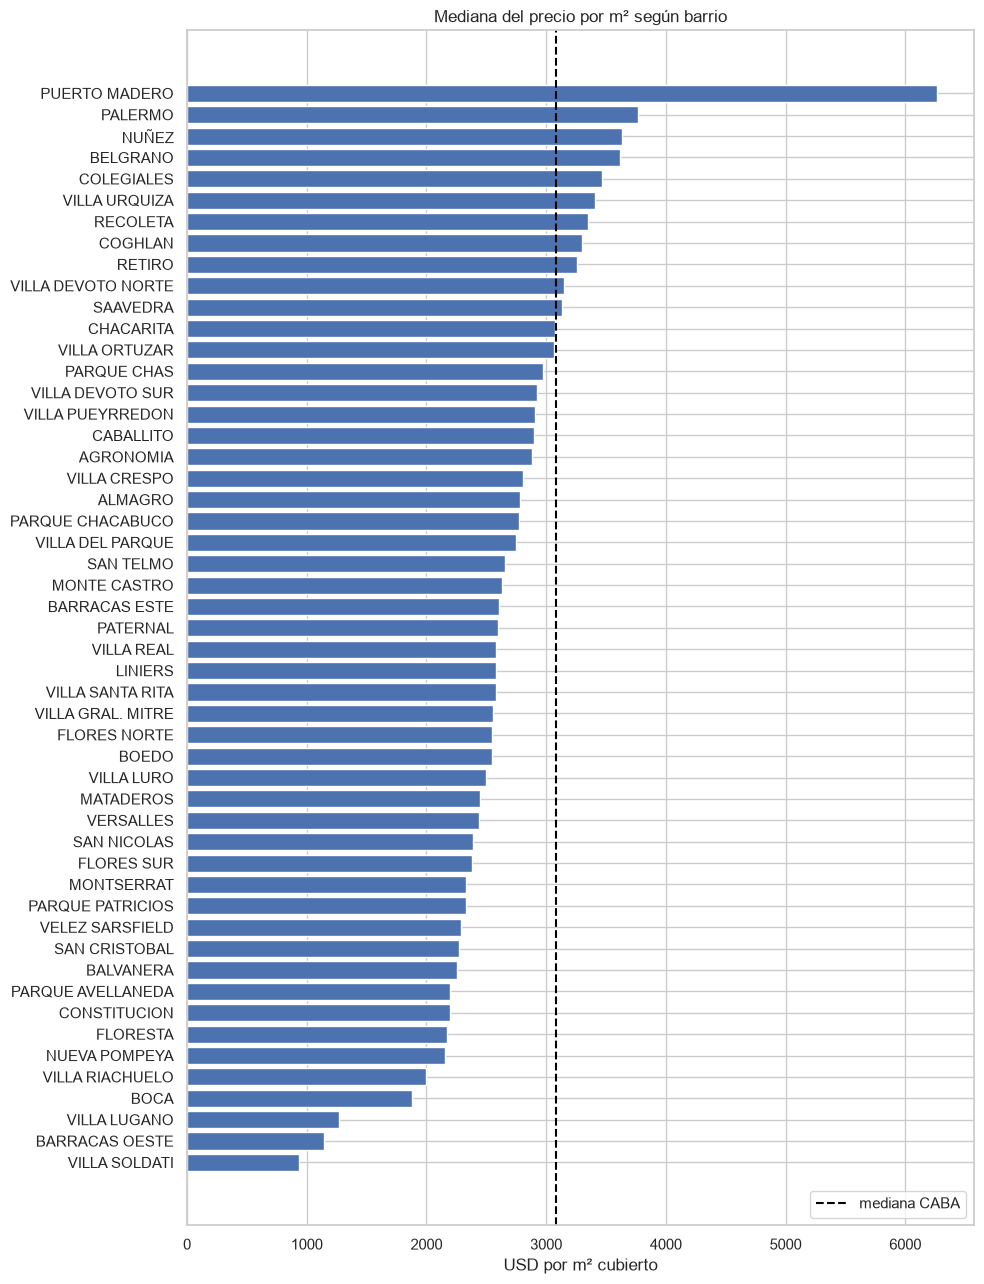

,mediana,publicaciones
BARRIOS_1,,
PUERTO MADERO,"6,260.87",1515
PALERMO,"3,768.09",14408
NUÑEZ,"3,633.54",2671
VILLA LUGANO,"1,267.26",252
BARRACAS OESTE,"1,140.62",1
VILLA SOLDATI,931.71,22


In [19]:
por_barrio = (df.groupby('BARRIOS_1')['USD_M2']
              .agg(mediana='median', publicaciones='count')
              .sort_values('mediana'))

fig, eje = plt.subplots(figsize=(10, 13))
eje.barh(por_barrio.index, por_barrio['mediana'], color='#4c72b0')
eje.axvline(df['USD_M2'].median(), color='black', ls='--', label='mediana CABA')
eje.set_xlim(left=0)
eje.set_title('Mediana del precio por m² según barrio')
eje.set_xlabel('USD por m² cubierto')
eje.legend(loc='lower right')
plt.tight_layout()
plt.show()

por_barrio.sort_values('mediana', ascending=False).iloc[[0, 1, 2, -3, -2, -1]]

### 6.2 Circular — composición: ¿cómo se reparten las publicaciones por antigüedad?
Un único total, partes excluyentes y 5 categorías (condiciones de M5-3).

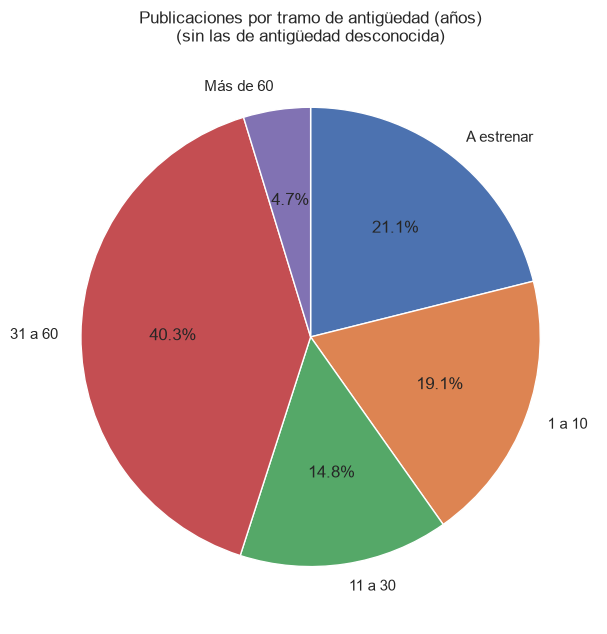

Antigüedad desconocida: 11,471 publicaciones (se imputan en el Pipeline)


,publicaciones,mediana_usd_m2
TRAMO_ANTIG,,
A estrenar,15588,"3,333.00"
1 a 10,14119,"3,580.00"
11 a 30,10899,"3,257.00"
31 a 60,29795,"2,738.00"
Más de 60,3485,"2,500.00"


In [20]:
composicion = df['TRAMO_ANTIG'].value_counts().sort_index()

fig, eje = plt.subplots(figsize=(6.5, 6.5))
eje.pie(composicion, labels=composicion.index, autopct='%1.1f%%', startangle=90,
        counterclock=False, colors=sns.color_palette('deep', len(composicion)))
eje.set_title('Publicaciones por tramo de antigüedad (años)\n(sin las de antigüedad desconocida)')
plt.tight_layout()
plt.show()

print(f"Antigüedad desconocida: {df['TRAMO_ANTIG'].isna().sum():,} publicaciones (se imputan en el Pipeline)")
df.groupby('TRAMO_ANTIG', observed=True)['USD_M2'].agg(publicaciones='count', mediana_usd_m2='median').round(0)

### 6.3 Líneas — evolución: ¿cambia el precio por m² a lo largo del año?
Una observación agregada por mes, en orden cronológico (MAYO no tiene datos).

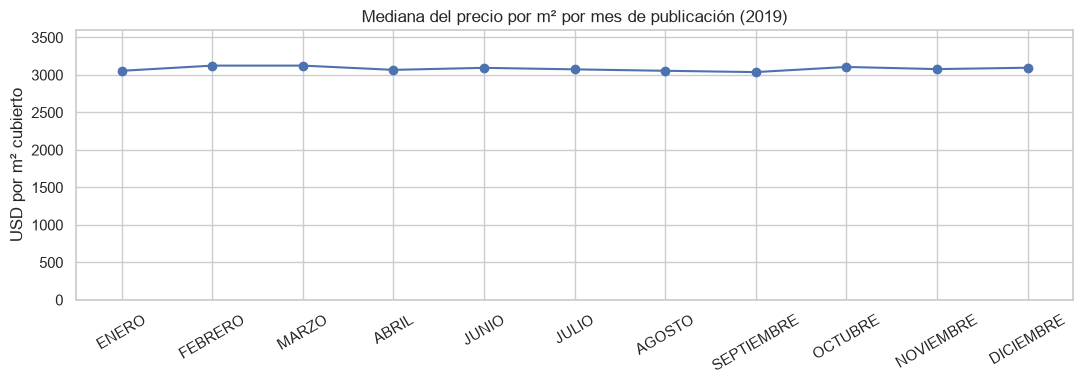

MES,ENERO,FEBRERO,MARZO,ABRIL,JUNIO,JULIO,AGOSTO,SEPTIEMBRE,OCTUBRE,NOVIEMBRE,DICIEMBRE
mediana,"3,056.00","3,125.00","3,125.00","3,068.00","3,095.00","3,075.00","3,056.00","3,038.00","3,107.00","3,078.00","3,097.00"
publicaciones,"3,966.00","6,692.00","6,712.00","4,325.00","15,470.00","4,761.00","8,912.00","8,868.00","10,427.00","7,859.00","7,365.00"


In [21]:
por_mes = df.groupby('MES')['USD_M2'].agg(mediana='median', publicaciones='count').reindex(MESES)

fig, eje = plt.subplots(figsize=(11, 4))
eje.plot(por_mes.index, por_mes['mediana'], marker='o')
eje.set_ylim(0, por_mes['mediana'].max() * 1.15)
eje.set_title('Mediana del precio por m² por mes de publicación (2019)')
eje.set_ylabel('USD por m² cubierto')
eje.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

por_mes.round(0).T

### 6.4 Dispersión — relación: ¿los departamentos más grandes tienen m² más caro?
Un punto por departamento. Asociación no implica causalidad (M5-3).

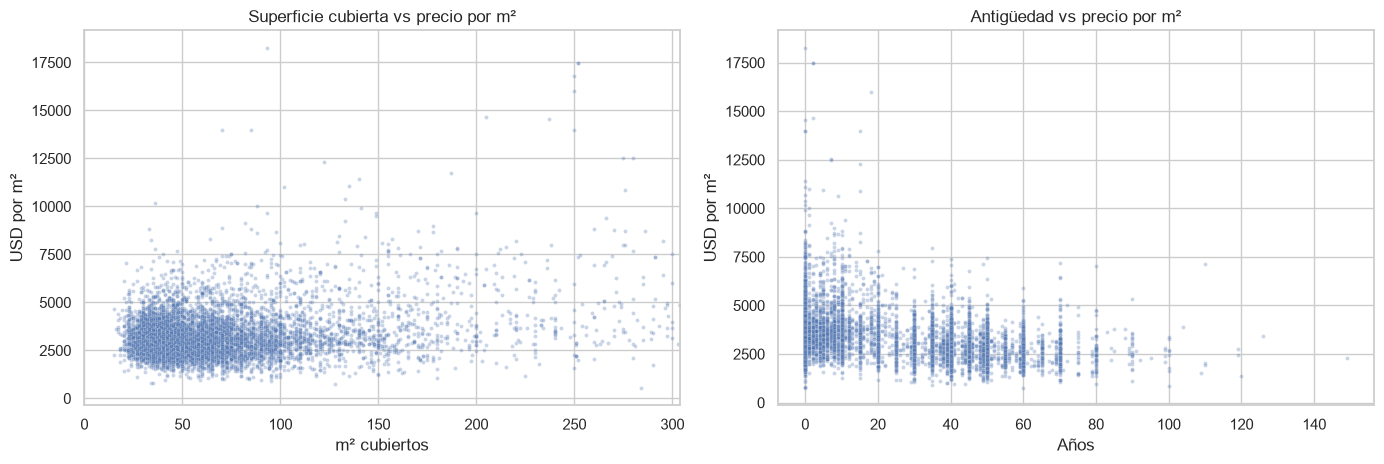

,Spearman con USD_M2
ANTIG,-0.37
LONGITUD,-0.01
AMBIENTES,0.02
M2CUB,0.10
M2TOTAL,0.17
BANOS,0.25
LATITUD,0.49


In [22]:
muestra = df.sample(8000, random_state=42)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.scatterplot(data=muestra, x='M2CUB', y='USD_M2', s=8, alpha=0.3, ax=ejes[0])
ejes[0].set_xlim(0, df['M2CUB'].quantile(0.99))
ejes[0].set_title('Superficie cubierta vs precio por m²')
ejes[0].set_xlabel('m² cubiertos')
ejes[0].set_ylabel('USD por m²')

sns.scatterplot(data=muestra, x='ANTIG', y='USD_M2', s=8, alpha=0.3, ax=ejes[1])
ejes[1].set_title('Antigüedad vs precio por m²')
ejes[1].set_xlabel('Años')
ejes[1].set_ylabel('USD por m²')
plt.tight_layout()
plt.show()

numericas = ['USD_M2', 'M2CUB', 'M2TOTAL', 'AMBIENTES', 'BANOS', 'ANTIG', 'LATITUD', 'LONGITUD']
df[numericas].corr(method='spearman')['USD_M2'].drop('USD_M2').round(2).sort_values().to_frame('Spearman con USD_M2')

Se usa la correlación de **Spearman** porque las variables son asimétricas y la relación no tiene por qué ser lineal.

### 6.5 Dispersión geográfica — mapa de precios
Cada punto es un departamento ubicado por coordenadas (sin SEPTIEMBRE).

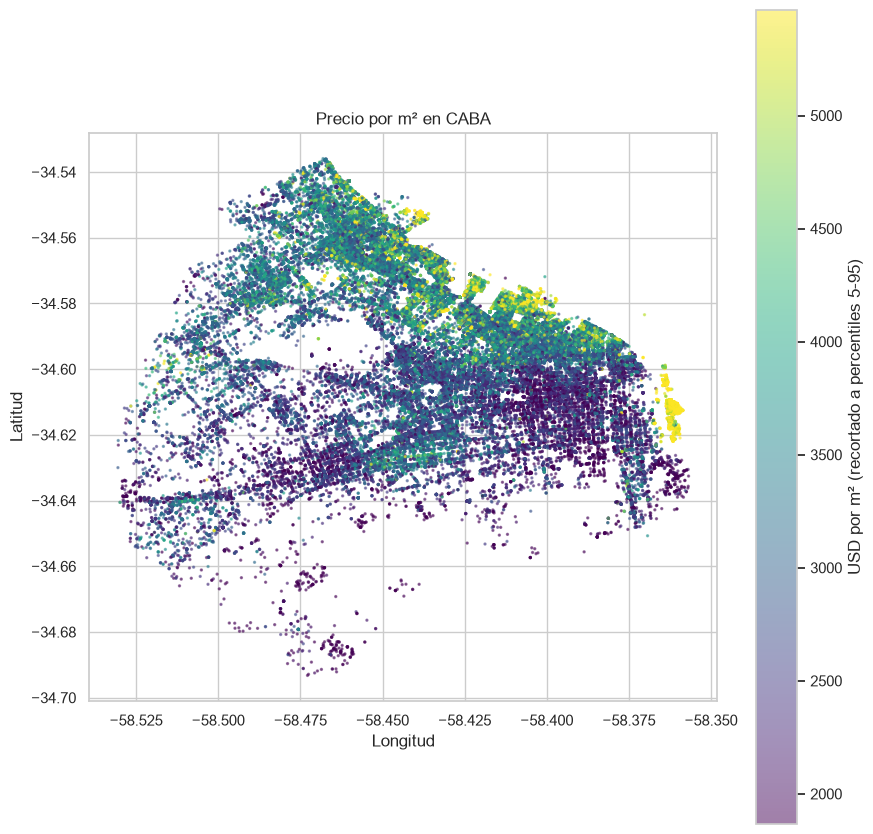

In [23]:
con_coord = df.dropna(subset=['LATITUD', 'LONGITUD'])
lim_inf, lim_sup = con_coord['USD_M2'].quantile([0.05, 0.95])

fig, eje = plt.subplots(figsize=(9, 8.5))
puntos = eje.scatter(con_coord['LONGITUD'], con_coord['LATITUD'],
                     c=con_coord['USD_M2'].clip(lim_inf, lim_sup), cmap='viridis', s=2, alpha=0.5)
fig.colorbar(puntos, ax=eje, label='USD por m² (recortado a percentiles 5-95)')
eje.set_title('Precio por m² en CABA')
eje.set_xlabel('Longitud')
eje.set_ylabel('Latitud')
eje.set_aspect('equal')
plt.tight_layout()
plt.show()

## 7. Variable objetivo y su distribución
*(M3-3 Hito A: "distribución de y".)*

**Criterio de segmentación** (justificado en el documento *Segmentación de valor – Departamentos CABA 2019*):
- **Medida:** precio publicado por m² **cubierto** (`USD_M2`), recalculado de forma homogénea para todos los meses (hallazgo de la sección 4).
- **Cortes:** relativos al mercado del año, no umbrales fijos → **terciles**: Económico, Medio y Premium, cada uno con un tercio de los departamentos.
- **Fundamento:** replica la descripción en tres niveles del Index de Zonaprop (*Mayor precio / Zona media / Menor precio*).
- **El precio no entra al modelo:** define el segmento; superficie, antigüedad, ambientes y ubicación lo predicen.

> ⚠️ Los cortes de esta sección son exploratorios. En el notebook de modelado los terciles se calculan **solo con el conjunto de entrenamiento** y luego se aplican al de prueba.

In [24]:
cortes = df['USD_M2'].quantile([1 / 3, 2 / 3])
print(f'Corte Económico / Medio: USD {cortes.iloc[0]:,.0f}/m²')
print(f'Corte Medio / Premium:   USD {cortes.iloc[1]:,.0f}/m²')

segmento = pd.qcut(df['USD_M2'], q=3, labels=['Económico', 'Medio', 'Premium'])
pd.DataFrame({
    'n': segmento.value_counts().sort_index(),
    '%': (segmento.value_counts(normalize=True).sort_index() * 100).round(2),
})

Corte Económico / Medio: USD 2,727/m²
Corte Medio / Premium:   USD 3,491/m²


,n,%
USD_M2,,
Económico,28553,33.45
Medio,28358,33.22
Premium,28446,33.33


In [25]:
# Perfil típico (mediana) de cada segmento.
df.assign(SEGMENTO=segmento).groupby('SEGMENTO', observed=True)[
    ['USD_M2', 'M2CUB', 'AMBIENTES', 'BANOS', 'ANTIG']
].median().round(1)

,USD_M2,M2CUB,AMBIENTES,BANOS,ANTIG
SEGMENTO,,,,,
Económico,"2,321.40",55.00,3.00,1.00,40.00
Medio,"3,087.70",50.00,2.00,1.00,29.00
Premium,"4,122.70",62.00,3.00,1.00,8.00


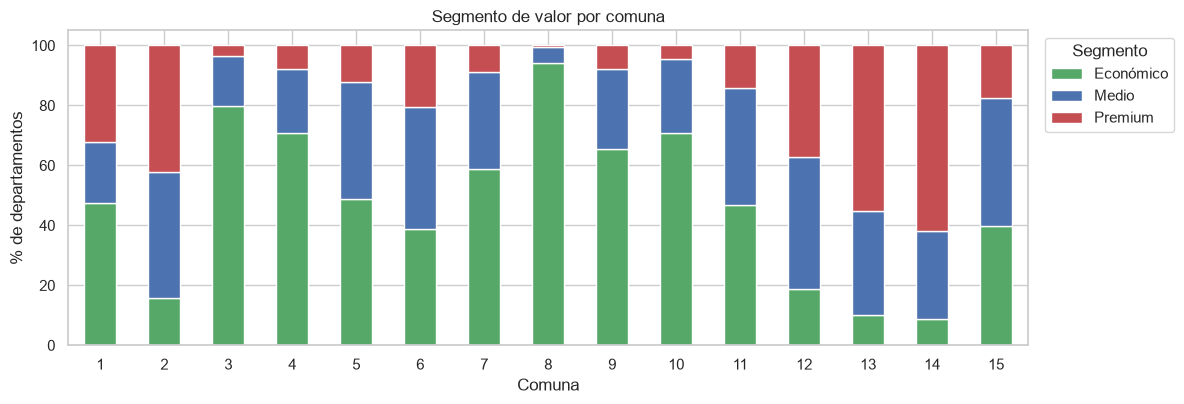

In [26]:
# Composición de segmentos por comuna.
pd.crosstab(df['COMUNAS'], segmento, normalize='index').mul(100).plot(
    kind='bar', stacked=True, figsize=(12, 4.2), color=['#55a868', '#4c72b0', '#c44e52'])
plt.title('Segmento de valor por comuna')
plt.ylabel('% de departamentos')
plt.xlabel('Comuna')
plt.legend(title='Segmento', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Definición de X e y y variables excluidas
*(M3-3 Hito A: "definición explícita de X e y; variables excluidas y razón".)*

In [27]:
OBJETIVO = 'SEGMENTO (terciles de USD_M2, calculados en train)'
VARIABLES_NUMERICAS = ['M2CUB', 'M2TOTAL', 'AMBIENTES', 'BANOS', 'ANTIG', 'LATITUD', 'LONGITUD']
VARIABLES_CATEGORICAS = ['BARRIOS_1', 'COMUNAS', 'TRAMO_ANTIG', 'MES']
EXCLUIDAS_DE_X = {
    COLUMNA_ID: 'Identificador para vincular SQLite y MongoDB; no describe al inmueble.',
    'USD_M2': 'Define la variable objetivo (fuga de información).',
    'PRECIOUSD': 'Precio publicado: no disponible al predecir (fuga). Se conserva solo para el análisis de sobrevaluación.',
}

print('y:', OBJETIVO)
print('X numéricas:', VARIABLES_NUMERICAS)
print('X categóricas:', VARIABLES_CATEGORICAS)
pd.concat([
    pd.Series(COLUMNAS_DESCARTADAS, name='motivo').to_frame().assign(etapa='Eliminada en la limpieza'),
    pd.Series(EXCLUIDAS_DE_X, name='motivo').to_frame().assign(etapa='En el dataset, fuera de X'),
]).rename_axis('columna')

y: SEGMENTO (terciles de USD_M2, calculados en train)
X numéricas: ['M2CUB', 'M2TOTAL', 'AMBIENTES', 'BANOS', 'ANTIG', 'LATITUD', 'LONGITUD']
X categóricas: ['BARRIOS_1', 'COMUNAS', 'TRAMO_ANTIG', 'MES']


,motivo,etapa
columna,,
OPERACION,Constante tras filtrar (solo ventas).,Eliminada en la limpieza
TIPO,Constante tras filtrar (solo departamentos).,Eliminada en la limpieza
AGE,81 % vacía; su único valor (EST = a estrenar) ...,Eliminada en la limpieza
DIRECCION,"Texto libre; la ubicación ya está en barrio, c...",Eliminada en la limpieza
CAMBIO,Tipo de cambio del mes; formato inconsistente ...,Eliminada en la limpieza
PRECIOARS,Mismo precio en pesos: redundante con PRECIOUSD.,Eliminada en la limpieza
PRECIOARSM,Mismo precio por m² en pesos: redundante.,Eliminada en la limpieza
PRECIOUSDM,Calculado con criterio distinto según el mes (...,Eliminada en la limpieza
ID_PROPIEDAD,Identificador para vincular SQLite y MongoDB; ...,"En el dataset, fuera de X"


## 9. Conclusiones
*(M1-1: el EDA sirve para entender la información disponible, identificar sesgos y generar hipótesis antes del modelado.)*

**Calidad de los datos**
- Se conservan **85.357 de 88.640 filas (96,3 %)**. Lo que más se pierde son avisos sin superficie cubierta válida (2.158) y publicaciones repetidas (1.087 entre las dos etapas de duplicados). Por precio por m² imposible se eliminan solo **10 avisos**.
- `PRECIOUSDM` venía calculado con dos criterios distintos (FEBRERO sobre m² totales). Sin el recálculo, la variable objetivo de febrero habría quedado sesgada.
- **IQR vs límites de dominio:** el IQR sobre el precio por m² habría eliminado 4.156 avisos, entre ellos el **74 % de Puerto Madero** y 1.641 de Palermo, que son precios reales. Se usan límites fijos (500–20.000 USD/m²) anclados en el mercado.
- **Antigüedad 0 = dato faltante en 8 de 11 meses:** 11.801 avisos tenían `ANTIG = 0` sin la marca "a estrenar", y el patrón depende del mes de carga. Quedan 11.471 nulos (13 %) que se imputan con indicador de faltante.
- **Sesgo a tener en cuenta:** SEPTIEMBRE no tiene coordenadas (8.868 filas, 10 %). Para esas filas, la ubicación queda representada solo por barrio y comuna.
- Hay barrios con muy pocas publicaciones (Barracas Oeste: 1; Villa Soldati: 22). En el Pipeline hay que usar `OneHotEncoder(handle_unknown='ignore')` para que no falle si aparece un barrio que no estaba en train.

**Qué se relaciona con el precio por m²**
- **La ubicación es el factor principal.** La mediana va de ~USD 6.260/m² en Puerto Madero y ~3.770 en Palermo a ~1.270 en Villa Lugano y ~930 en Villa Soldati. La latitud es la variable numérica más correlacionada (Spearman 0,49): el norte de la ciudad es más caro, y el mapa lo confirma.
- **La antigüedad pesa en segundo lugar** (Spearman −0,37, más fuerte que antes de separar los "sin dato"). Los departamentos de 1 a 10 años tienen la mediana más alta (~3.580) y los de más de 60 años la más baja (~2.500).
- **La superficie y los ambientes se relacionan poco con el precio *por m²*** (Spearman entre 0,02 y 0,17); los baños algo más (0,25), probablemente como indicador de categoría del inmueble. El segmento no queda determinado por el tamaño.
- **El mes de publicación no muestra variación** (medianas entre ~3.040 y ~3.125 USD/m²). Es candidato a no aportar al modelo.

**Variable objetivo**
- Con terciles, las clases quedan **balanceadas (~33 % cada una)**; cortes exploratorios en ~USD 2.727 y ~3.491/m².
- Perfil típico: *Económico* ≈ 40 años de antigüedad, *Medio* ≈ 29, *Premium* ≈ 8. El tamaño es similar en los tres segmentos (50–62 m²).

**Hipótesis para el modelado**
1. Un modelo que combine barrio/coordenadas y antigüedad debería superar claramente al `DummyClassifier` (~33 % de accuracy con clases balanceadas).
2. Los modelos de árboles (Random Forest, gradient boosting) deberían aprovechar mejor las coordenadas que la Regresión Logística, porque la relación entre latitud/longitud y precio no es lineal.
3. Las confusiones más esperables están entre clases vecinas (Económico–Medio y Medio–Premium), no entre los extremos.
4. Mantener el segmento de lujo (límites fijos en lugar de IQR) no debería perjudicar el recall de Premium: son los casos más fáciles de reconocer por ubicación. Se puede verificar comparando ambas limpiezas sobre el mismo conjunto de prueba.

## 10. Dataset limpio y persistencia
La carga a la base de datos (Tabla 1 de la consigna, SQLite) no se hace desde el notebook: la realiza `scripts/cargar_bd.py`, que reutiliza `cargar_dbf` y `limpiar_datos`. Así el notebook queda para el análisis y el script para el flujo reproducible.

In [28]:
print(f'Dataset limpio: {df.shape[0]:,} filas x {df.shape[1]} columnas')
print('Columnas:', df.columns.tolist())

Dataset limpio: 85,357 filas x 14 columnas
Columnas: ['ID_PROPIEDAD', 'ANTIG', 'M2TOTAL', 'M2CUB', 'AMBIENTES', 'BANOS', 'PRECIOUSD', 'BARRIOS_1', 'COMUNAS', 'MES', 'LATITUD', 'LONGITUD', 'USD_M2', 'TRAMO_ANTIG']
